<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/Practica_Clasificadores_Integrante_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
# ==========================================
# CELDA 1: IMPORTAR BIBLIOTECAS
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import time

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [42]:
# ==========================================
# CELDA 2: CARGAR DATASET WINE
# ==========================================

url = "https://raw.githubusercontent.com/paolamrk/Practica3_MachineLearning/refs/heads/main/wine_preparado.csv"

df_wine = pd.read_csv(url)

print("Dataset Wine cargado correctamente")

display(df_wine.head())

Dataset Wine cargado correctamente


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase,holdout,fold
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,train,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,train,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,test,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,train,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,train,3


In [43]:
# ==========================================
# CELDA 3: DIMENSIONES Y COLUMNAS
# ==========================================

print("Dimensiones del dataset:", df_wine.shape)
print("Cantidad de muestras:", df_wine.shape[0])
print("Cantidad de columnas:", df_wine.shape[1])

print("\nColumnas del dataset:")
for columna in df_wine.columns:
    print("-", columna)

Dimensiones del dataset: (178, 16)
Cantidad de muestras: 178
Cantidad de columnas: 16

Columnas del dataset:
- alcohol
- malic_acid
- ash
- alcalinity_of_ash
- magnesium
- total_phenols
- flavanoids
- nonflavanoid_phenols
- proanthocyanins
- color_intensity
- hue
- od280/od315_of_diluted_wines
- proline
- Clase
- holdout
- fold


In [44]:
# ==========================================
# CELDA 4: ESTADISTICAS DESCRIPTIVAS
# ==========================================

caracteristicas = df_wine.drop(
    columns=["Clase", "holdout", "fold"]
)

display(caracteristicas.describe())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [45]:
# ==========================================
# CELDA 5: VALORES FALTANTES
# ==========================================

print("Valores faltantes por columna:")

print(df_wine.isnull().sum())

print("\nTotal de valores faltantes:")

print(df_wine.isnull().sum().sum())

Valores faltantes por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
Clase                           0
holdout                         0
fold                            0
dtype: int64

Total de valores faltantes:
0


Distribución de clases:
Clase
0    59
1    71
2    48
Name: count, dtype: int64


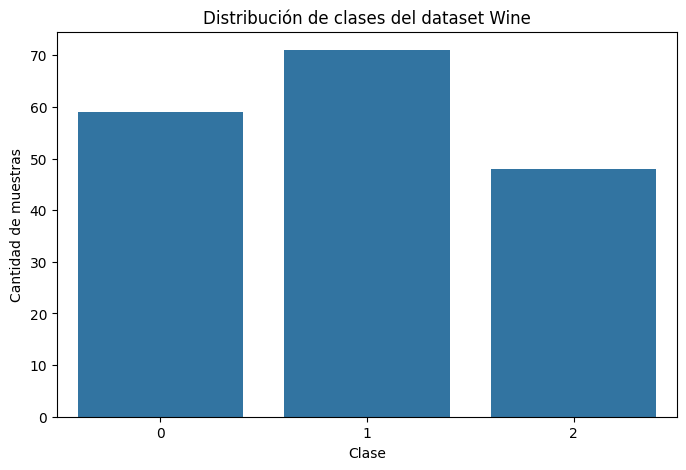

In [46]:
# ==========================================
# CELDA 6: DISTRIBUCION DE CLASES
# ==========================================

print("Distribución de clases:")

print(df_wine["Clase"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_wine,
    x="Clase"
)

plt.title("Distribución de clases del dataset Wine")

plt.xlabel("Clase")

plt.ylabel("Cantidad de muestras")

plt.show()

In [47]:
# ==========================================
# CELDA 7: SEPARAR X E Y
# ==========================================

# Características químicas
X_wine = df_wine.drop(
    columns=["Clase", "holdout", "fold"]
)

# Etiquetas de clasificación
y_wine = df_wine["Clase"]

print("Dimensiones de características:", X_wine.shape)

print("Dimensiones de etiquetas:", y_wine.shape)

Dimensiones de características: (178, 13)
Dimensiones de etiquetas: (178,)


In [48]:
# ==========================================
# CELDA 8: DIVISION DE ENTRENAMIENTO Y PRUEBA
# ==========================================

# Identificar las muestras de entrenamiento
X_train = X_wine[
    df_wine["holdout"] == "train"
].values

y_train = y_wine[
    df_wine["holdout"] == "train"
].values


# Identificar las muestras de prueba
X_test = X_wine[
    df_wine["holdout"] == "test"
].values

y_test = y_wine[
    df_wine["holdout"] == "test"
].values


# Mostrar resultados
print("Datos de entrenamiento:", X_train.shape)

print("Datos de prueba:", X_test.shape)

print("Etiquetas de entrenamiento:", y_train.shape)

print("Etiquetas de prueba:", y_test.shape)

Datos de entrenamiento: (124, 13)
Datos de prueba: (54, 13)
Etiquetas de entrenamiento: (124,)
Etiquetas de prueba: (54,)


In [49]:
url_sint = "https://raw.githubusercontent.com/paolamrk/Practica3_MachineLearning/refs/heads/main/sintetico_preparado.csv"

df_sint = pd.read_csv(url_sint)

print("Dimensiones:", df_sint.shape)
print("Columnas:", list(df_sint.columns))
print("Valores de holdout:", df_sint["holdout"].value_counts())
print("Clases:", df_sint["Clase"].value_counts().sort_index())

Dimensiones: (1000, 9)
Columnas: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'Clase', 'holdout', 'fold']
Valores de holdout: holdout
train    700
test     300
Name: count, dtype: int64
Clases: Clase
0    325
1    331
2    344
Name: count, dtype: int64


In [50]:
X_sint = df_sint.drop(columns=["Clase", "holdout", "fold"])
y_sint = df_sint["Clase"]

Xs_train = X_sint[df_sint["holdout"] == "train"].values
ys_train = y_sint[df_sint["holdout"] == "train"].values
Xs_test  = X_sint[df_sint["holdout"] == "test"].values
ys_test  = y_sint[df_sint["holdout"] == "test"].values

print("Train:", Xs_train.shape, "| Test:", Xs_test.shape)

Train: (700, 6) | Test: (300, 6)


In [51]:
class OneNN:
    """Clasificador 1-NN desde cero (distancia euclidiana)."""

    def fit(self, X, y):
        # 1-NN no "aprende" nada: solo guarda el entrenamiento
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predicciones = []
        for muestra in X:
            # distancia euclidiana a todas las muestras de entrenamiento
            distancias = np.sqrt(np.sum((self.X_train - muestra) ** 2, axis=1))
            # etiqueta del vecino más cercano
            predicciones.append(self.y_train[np.argmin(distancias)])
        return np.array(predicciones)

In [52]:
modelo_1nn = OneNN().fit(X_train, y_train)
y_pred_1nn = modelo_1nn.predict(X_test)
print("Exactitud 1-NN:", accuracy_score(y_test, y_pred_1nn))

Exactitud 1-NN: 0.7037037037037037


In [53]:
from sklearn.neighbors import KNeighborsClassifier

ref = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
print("Exactitud sklearn (referencia):", accuracy_score(y_test, ref.predict(X_test)))
print("¿Mismas predicciones?", np.array_equal(y_pred_1nn, ref.predict(X_test)))

Exactitud sklearn (referencia): 0.7037037037037037
¿Mismas predicciones? True


In [54]:
from sklearn.svm import SVC

svm = SVC()   # parámetros por defecto: kernel='rbf', C=1.0, gamma='scale'
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
print("Exactitud SVM:", accuracy_score(y_test, y_pred_svm))

Exactitud SVM: 0.6666666666666666


In [55]:
print("Clases en train:\n", pd.Series(y_train).value_counts().sort_index())
print("Clases en test:\n", pd.Series(y_test).value_counts().sort_index())

print("\nMedia train:", np.round(X_train.mean(axis=0), 2))
print("Desv. train:", np.round(X_train.std(axis=0), 2))
print("Media test: ", np.round(X_test.mean(axis=0), 2))

print("\nMatriz de confusión 1-NN:\n", confusion_matrix(y_test, y_pred_1nn))

Clases en train:
 0    41
1    50
2    33
Name: count, dtype: int64
Clases en test:
 0    18
1    21
2    15
Name: count, dtype: int64

Media train: [1.2960e+01 2.2900e+00 2.3600e+00 1.9670e+01 1.0004e+02 2.2900e+00
 2.0100e+00 3.6000e-01 1.6100e+00 4.9900e+00 9.5000e-01 2.6000e+00
 7.4833e+02]
Desv. train: [8.1000e-01 1.0600e+00 2.7000e-01 3.3700e+00 1.5170e+01 6.2000e-01
 9.5000e-01 1.2000e-01 5.8000e-01 2.3700e+00 2.3000e-01 6.8000e-01
 3.0682e+02]
Media test:  [1.3100e+01 2.4500e+00 2.3700e+00 1.9100e+01 9.9060e+01 2.3000e+00
 2.0800e+00 3.7000e-01 1.5600e+00 5.2000e+00 9.7000e-01 2.6400e+00
 7.4359e+02]

Matriz de confusión 1-NN:
 [[14  3  1]
 [ 1 15  5]
 [ 1  5  9]]


In [56]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Xr, yr = load_wine(return_X_y=True)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    Xr, yr, test_size=0.3, stratify=yr, random_state=42
)

esc = StandardScaler().fit(Xr_tr)
ref1 = KNeighborsClassifier(n_neighbors=1).fit(esc.transform(Xr_tr), yr_tr)
print("1-NN con Wine de sklearn:", accuracy_score(yr_te, ref1.predict(esc.transform(Xr_te))))

1-NN con Wine de sklearn: 0.9629629629629629


In [57]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().fit(X_train)       # se ajusta SOLO con train
X_train_esc = escalador.transform(X_train)
X_test_esc  = escalador.transform(X_test)       # test solo se transforma

In [58]:
modelo_1nn = OneNN().fit(X_train_esc, y_train)
y_pred_1nn = modelo_1nn.predict(X_test_esc)
print("Exactitud 1-NN:", accuracy_score(y_test, y_pred_1nn))

svm = SVC().fit(X_train_esc, y_train)
y_pred_svm = svm.predict(X_test_esc)
print("Exactitud SVM:", accuracy_score(y_test, y_pred_svm))

Exactitud 1-NN: 0.9629629629629629
Exactitud SVM: 0.9814814814814815
